# Quant Course
## Monte Carlo method, variance reduction

## Martingale Pricing
    
The price of a product with some payoff function $Payoff$ can be calculated as the expected value of the discounted payoff under risk neutral measure. We assume deterministic interest rate so the discount factor can be moved out from the expected value:

$$ V(t) = e^{-r(T-t)}\mathbb{E}[Payoff(S_T)|F_t] $$

We will work in the Black-Scholes model where the underlying follows 

$$ dS_t = rS_tdt + \sigma S_tdW_t $$


## Estimating the expected payoff

Law of large numbers: Expected value can be estimated with the sample mean

$$ m = E[X] \approx \frac{1}{N}\sum_iX_i $$ 



$$ V(t) = e^{-r(T-t)}\mathbb{E}[Payoff(S_T)] $$

* Generate n independent samples from $S_T$
* Evaluate the payoff function on the samples and take mean

We implement payoff function for each contract so the second step is easy, the complication arise at the first step.

In the general case we dont know the distribution of $S_T$, we only know it's inital value at some time $t$ and we have an assumption on it's dinamic (our market model). How to obtain samples from $S_T$?

## Euler–Maruyama method

consider the following stochastic diff equation:

$$ dS_t = \mu(t, S_t) dt + \sigma(t,S_t)dW_t $$

One can approximate the solution numerically 

* partition the time interval of $[0,T]$ into $N$ subintervals: $\Delta T = T/N$,   $ \quad t_i = i*\Delta T$
* we know the stock price today $S_0$. We approximate the stock price at the next timepoint:
$$ S_{t_{i+1}} = S_{t_i} + \mu(t_i, S_{t_i}) \Delta T + \sigma(t_i,S_{t_i}) \cdot (W_{t_{i+1}} - W_{t_i}) $$
* $W_t$ is a brownian motion, it's increments are independent normals:
$$ W_{t_{i+1}} - W_{t_i} \sim \mathcal{N}(0,t_{i+1}-t_i) $$
$$ W_{t_{i+1}} - W_{t_i} = \sqrt{\Delta T}\epsilon_i, \quad \epsilon_i\sim \mathcal{N}(0,1)$$

# Milstein method

Milstein method improves the accuracy of the Euler method by adding a correction term. Les sigma et les mu étaient considérés constants sur i-i+1, ce n'est plus le cas ici. Voir pourquoi cette formule et les weak/strong convergence. 

$$ 
S_{t_{i+1}} = 
S_{t_i} + \underbrace{\mu(t_i, S_{t_i}) \Delta T + \sigma(t_i,S_{t_i}) \cdot (W_{t_{i+1}} - W_{t_i}) }_{\text{Euler step}} 
+\underbrace{\frac{1}{2}(\frac{\partial}{\partial S}\sigma(t_i,S_{t_i})) \sigma(t_i,S_{t_i}) ((W_{t_{i+1}} - W_{t_i})^2-\Delta T)}_{\text{correction}} $$

It requires the derivative of the diffusion term. the correction term vanishes when $\sigma(t,S_t)$ does not depend on the spot and Milstein method become identical to Euler.

Euler: weak convergence order of 1, strong convergence order of 1/2

Milstein: weak convergence order of 1, strong convergence order of 1



## Solution to the SDE in the BS model

In BS model the risky asset follows GBM:

$$ dS_t = rS_t dt + \sigma S_tdW_t $$

For this relatively simple SDE the exact solution is known:

$$ S_t = S_0 e^{(r-\frac{\sigma^2}{2})t+\sigma W_t} $$

If we only need samples from $S_T$ we can simulate it directly, no need for partitioning the time interval and simulate the stock price for (from the contract's point of view) useless time points!

## Random number generation

We will use pseudo random numbers: The generated numbers will be statistically random, but if we fix a seed, always the same numbers will be generated. Donc générer avec différentes seeds avec une fonction numpy. 

How many random numbers will be needed?

* For a single path, we will need as many $\epsilon$ as the number of simulation tenors. 

* Therefor the total number of $\epsilon$ needed is <b>NumberOfPaths * NumberOfSimulTenors<b>

## Simulation tenors

<img src="./img/timegrid.png" style="margin-left:auto; margin-right:auto; width: 1500px;" />

<img src="./img/mc_code_structure.png" style="margin-left:auto; margin-right:auto; width: 1500px;" />

## Monte Carlo Error

In monte carlo we estimate the PV of the trade by an empirical mean

$$ PV = \frac{1}{N}\sum_{i=1}^NX_i $$ 

PV itself is a random variable here with some variance, therefore there is some uncertanity in the PV.

$$ VAR[PV] = VAR\left[\frac{1}{N}\sum_{i=1}^NX_i\right] = \frac{1}{N^2}\sum_{i=1}^NVAR[X_i] = \frac{1}{N}VAR[X]$$

The standard deviation of PV decreases with $\sqrt{N}$, and we can approximate the 95% confidence interval around PV. 

$$ \sigma^{MC} = \sqrt{VAR[PV]} = \frac{\sigma^X}{\sqrt{N}} \qquad CI = [PV-1.96*\sigma^{MC},PV+1.96*\sigma^{MC}]$$




## Excercise:

Implement the follwoing methods:
- evolve_simulated_spot for exact method
- simulate_spot_path

Price a fwd/european option with analytic and MC method

Change the number of simulation paths and see how MC noise changes

In [1]:
import os 
import sys

sys.path.append("..\..\..")

from src.pricer import *
MarketData.initialize()

<>:4: SyntaxWarning: invalid escape sequence '\.'
<>:4: SyntaxWarning: invalid escape sequence '\.'
C:\Users\ledui\AppData\Local\Temp\ipykernel_22836\3936141212.py:4: SyntaxWarning: invalid escape sequence '\.'
  sys.path.append("..\..\..")


QuantCourseBP 5048aa3da567a8a8590e0ab9fac96b4c48a41432*


In [2]:
und = Stock.TEST_COMPANY
ls = LongShort.LONG
strike = 1.2
expiry = 1
strike_level = strike * MarketData.get_spot()[und]

model = FlatVolModel(und)

contract_fwd = ForwardContract(und, ls, strike_level, expiry)
contract_opt = EuropeanContract(und, PutCallFwd.PUT, ls, strike_level, expiry)

pricer_fwd_an = ForwardAnalyticPricer(contract_fwd, model, Params())
pricer_opt_an = EuropeanAnalyticPricer(contract_opt, model, Params())



In [3]:
# import xy

und = Stock.TEST_COMPANY
ls = LongShort.LONG
strike = 1.2
expiry = 1
strike_level = strike * MarketData.get_spot()[und]

model = FlatVolModel(und)

contract_fwd = ForwardContract(und, ls, strike_level, expiry)
contract_opt = EuropeanContract(und, PutCallFwd.PUT, ls, strike_level, expiry)

pricer_fwd_an = ForwardAnalyticPricer(contract_fwd, model, Params())
pricer_opt_an = EuropeanAnalyticPricer(contract_opt, model, Params())

mc_params = MCParams(num_of_path=10000,
                     tenor_frequency=0,
                     antithetic=False,
                     standardize=False,
                     control_variate=False,
                     seed=1,
                     evolve_spot_method=MCNumMethod.EXACT)

pricer_fwd_mc = GenericMCPricer(contract_fwd, model, mc_params)
pricer_opt_mc = GenericMCPricer(contract_opt, model, mc_params)

fv_fwd_an = pricer_fwd_an.calc_fair_value()
fv_fwd_mc = pricer_fwd_mc.calc_fair_value_with_ci()

fv_opt_an = pricer_opt_an.calc_fair_value()
fv_opt_mc = pricer_opt_mc.calc_fair_value_with_ci()

pricer_opt_mc.params.evolve_spot_method = MCNumMethod.EULER
pricer_opt_mc.params.tenor_frequency = 4
fv_opt_mc_e = pricer_opt_mc.calc_fair_value_with_ci()

print("FORWARD AN: " + str(fv_fwd_an))
print("FORWARD MC: " + str(fv_fwd_mc))
print("OPTION AN: " + str(fv_opt_an))
print("OPTION MC: " + str(fv_opt_mc))
print("OPTION MC Euler: " + str(fv_opt_mc_e))

FORWARD AN: -14.147530940085687
FORWARD MC: (np.float64(-13.60287113415415), (np.float64(-14.184075580227448), np.float64(-13.021666688080849)))
OPTION AN: 20.594305984211573
OPTION MC: (np.float64(20.253539136216038), (np.float64(19.88194754958432), np.float64(20.625130722847754)))
OPTION MC Euler: (np.float64(20.17854840821545), (np.float64(19.80342131539317), np.float64(20.55367550103773)))


In [4]:
paths = [100, 500, 1000, 5000, 10000, 50000]
for p in paths:
    pricer_opt_mc.params.num_of_paths = p
    print(pricer_opt_mc.calc_fair_value_with_ci())

(np.float64(18.926448306659), (np.float64(15.254771279627176), np.float64(22.598125333690824)))
(np.float64(18.788700289346277), (np.float64(17.109178463546453), np.float64(20.4682221151461)))
(np.float64(19.361744758496375), (np.float64(18.169716311663276), np.float64(20.553773205329477)))
(np.float64(20.186520940121085), (np.float64(19.652449353608805), np.float64(20.720592526633364)))
(np.float64(20.17854840821545), (np.float64(19.80342131539317), np.float64(20.55367550103773)))
(np.float64(20.298908040225825), (np.float64(20.129015474967176), np.float64(20.46880060548448)))


# Variance reduction methods

* Standardizing the normal randoms

* Antithetic random numbers 
    
* Control Variate

## Variance Reduction

### Standardizing:

We generate $n$ independent std normals

$$\epsilon = \{\epsilon_1, ..., \epsilon_n\} \qquad \epsilon_i \sim \mathcal{N}(0,1) \, iid$$

The sample itself wont have exactly 0 mean and 1 std dev, so we can adjust it with the sample's mean and std dev:

$$\epsilon^* = \frac{\epsilon - \mu}{\sigma}$$  

### Antithetic randoms:

Once epsilon is generated, flip all the random's sign and reuse them:

$$ \epsilon^* =  \{\epsilon_1, ..., \epsilon_n, -\epsilon_1, ..., -\epsilon_n\} $$


## Variance Reduction, Control Variate

The estimator given control variate Y and parameter b is
$$ X^{CV} = X + b(Y - E[Y]) $$ X est le Payoff


The new estimator is still unbiased:

$$ E[X^{CV}] = E[X] + b(E[Y] - E[E[Y]]) = E[X] $$

Let's see the variance of the new estimator:

$$ Var[X^{CV}] = Var[X] + Var[b*(Y-E[Y])] + 2Cov[X,b(Y - E[Y] )] = Var[X] + b^2Var[Y] + 2bCov[X,Y] $$

Once we decided what control variate Y we will use, we can choose b such that the modified estimator's variance is minimised:

with $ b^*=-\frac{Cov[X,Y]}{Var[Y]} $, the variance of the new estimator will decrease

$$ Var[X^{CV}] = Var[X] - \frac{(Cov[X,Y])^2}{Var[Y]} $$


## Variance Reduction, Control Variate

$$ X^{CV} = X + b(Y - E[Y])\qquad b^*=-\frac{Cov[X,Y]}{Var[Y]} $$

For example for options one can choose forwards as control variate:

$$ X = (S_T - K)^+ $$
$$ Y = S_T - K $$

1, How to determine $b^*$?

* We will simulate n realization of $S_T$
* Evaluate the payoffs of $X$ and $Y$ on each $S^{(i)}_T$
* Use these samples $[X^{(1)}, ...]$, $[Y^{(1)}, ...]$  to estimate $Cov[X,Y]$ and $Var[Y]$

2, How to determine $E[Y]$?

We can only use such contracts as control variates, which have analytic pricing formula. In that case, we can create an analytic pricer for the contract and invoke it's calc_fair_value method. Revoir cette affirmation


## Excercise

Implement the following methods in generic MC pricer:
- calc_fair_value_with_ci


- apply_control_var_adj

Test the various noise reduction methods.

How does control variate perform for OTM,ATM,ITM options? Why?


In [5]:
und = Stock.TEST_COMPANY
ls = LongShort.LONG
strike = 1
expiry = 1
strike_level = strike * MarketData.get_spot()[und]
contract_opt = EuropeanContract(und, PutCallFwd.CALL, ls, strike_level, expiry)

model = FlatVolModel(und)

numofpath = 20000

mc_params_0 = MCParams(num_of_path=numofpath,
                       tenor_frequency=0,
                       antithetic=False,
                       standardize=False,
                       control_variate=False,
                       seed=1,
                       evolve_spot_method = MCNumMethod.EXACT)

mc_params_1 = MCParams(num_of_path=numofpath,
                       tenor_frequency=0,
                       antithetic=True,
                       standardize=False,
                       control_variate=False,
                       seed=1,
                       evolve_spot_method = MCNumMethod.EXACT)

mc_params_2 = MCParams(num_of_path=numofpath,
                       tenor_frequency=0,
                       antithetic=False,
                       standardize=True,
                       control_variate=False,
                       seed=1,
                       evolve_spot_method = MCNumMethod.EXACT)

mc_params_3 = MCParams(num_of_path=numofpath,
                       tenor_frequency=0,
                       antithetic=False,
                       standardize=False,
                       control_variate=True,
                       seed=1,
                       evolve_spot_method = MCNumMethod.EXACT)

for param in [mc_params_0, mc_params_1, mc_params_2, mc_params_3]:
    pricer_opt_mc = GenericMCPricer(contract_opt, model, param)
    price = pricer_opt_mc.calc_fair_value_with_ci()
    pv = price[0]
    stdDev = (price[1][1]-pv)/1.96
    print("PV: " + str(pv) + "     MonteCarlo StdDev: " + str(stdDev))

PV: 14.539067921948966     MonteCarlo StdDev: 0.16063236176369067
PV: 14.340077547938764     MonteCarlo StdDev: 0.1604705803056927
PV: 14.446322956162208     MonteCarlo StdDev: 0.16011957584389916
PV: 14.271577856571474     MonteCarlo StdDev: 0.05995129436877271


### Excercise - Implementing Asian Option (Average Price Option):

Consider a set of avereging time points: $t_1<t_2<...<t_N=T$.

The payoff of an asian option at time $T$ is $max\{\frac{1}{N}\sum_{i=1}^NS(t_i), K\}$

Implement the contract with uniformly distributed observation points. $\{i * T/num\_obs : i = 1,...,num\_obs\}$, where num_obs is the number of observations

## Assignments

In both tasks:
- extend the code in the repositories src folder for the implementation part a)
- write the code in jupyter for part b)

<b> 8/1 Implement and test Milstein scheme <b>

a, Implement the Milstein method in the MCMethod class's evolve_simulated_spot method, test it by pricing an option with it and compare the PV with analytic (7p)

b, Compare the strong convergence of Euler and Milstein methods as we reduce the size of timesteps. (8p)
    
   - The strong convergence error with timestep dt is measured as the expected pathwise abolute error at time T between the approximation and exact solution. 
   $ \epsilon^{strong}(dt) = E[|S^{approx, dt}(T) - S^{exact}(T)|] $

    
<b>8/2 Improve delta calculation for FlatVol model <b>

In BS model the spot at time t is $ S_t = S_0 e^{(r-\frac{\sigma^2}{2})t+\sigma W_t} $. Knowing this, when we bump the spot we dont have to resimulate the spot, instead we can obtain it by scaling the inital simulation: $ S^{bumped}_t = S_0*(1+\delta) e^{(r-\frac{\sigma^2}{2})t+\sigma W_t} $.

a, implement this delta calculation method for MonteCarlo pricer (10p) 

b, compare the value and the calculation time of the improved delta with the default bump and revaluation delta. (5p)


In [6]:
#FIRST PART OF THE HOMEWORK 

#tests of the Milstein's method, implemented in the numerical_method file

pricer_opt_mc_milstein = GenericMCPricer(contract_opt, model, mc_params)
pricer_opt_mc_milstein.params.evolve_spot_method = MCNumMethod.MILSTEIN
pricer_opt_mc_milstein.params.tenor_frequency = 4
fv_opt_mc_milstein = pricer_opt_mc_milstein.calc_fair_value_with_ci()

pricer_fwd_mc_milstein = GenericMCPricer(contract_fwd, model, mc_params)
pricer_fwd_mc_milstein.params.evolve_spot_method = MCNumMethod.MILSTEIN
pricer_fwd_mc_milstein.params.tenor_frequency = 4
fv_fwd_mc_milstein = pricer_fwd_mc_milstein.calc_fair_value_with_ci()

print("FORWARD AN: " + str(fv_fwd_an))
print("FORWARD MC Milstein: " + str(fv_fwd_mc_milstein))
print("OPTION AN: " + str(fv_opt_an))
print("OPTION MC Milstein: " + str(fv_opt_mc_milstein))

FORWARD AN: -14.147530940085687
FORWARD MC Milstein: (np.float64(-14.054912313814407), (np.float64(-14.309706886536988), np.float64(-13.800117741091826)))
OPTION AN: 20.594305984211573
OPTION MC Milstein: (np.float64(14.173656497058577), (np.float64(13.978576720393326), np.float64(14.368736273723828)))


In [7]:
import numpy as np
errors_euler = []
errors_milstein = []
frequencies = []
square_root_frequencies = []

#size of timesteps:
tenor_frequencies = np.arange(5, 20, 1)

for i in tenor_frequencies:
    mc_params_second = MCParams(num_of_path=1000, tenor_frequency= i, antithetic=False, standardize=False, control_variate=False, seed=1, 
                           evolve_spot_method=MCNumMethod.EXACT)

    st_exact_gen = MCMethodFlatVol(contract_opt, model, mc_params_second)
    st_euler_gen = MCMethodFlatVol(contract_opt, model, mc_params_second)
    st_milstein_gen = MCMethodFlatVol(contract_opt, model, mc_params_second)

    #the exact S_t 
    st_exact = st_exact_gen.simulate_spot_paths()

    #the S_t obtained with Euler's method
    st_euler_gen.params.evolve_spot_method = MCNumMethod.EULER
    st_euler = st_euler_gen.simulate_spot_paths()

    #the S_t obtained with Milstein's method
    st_milstein_gen.params.evolve_spot_method = MCNumMethod.MILSTEIN
    st_milstein = st_milstein_gen.simulate_spot_paths()

    error_euler = np.abs(st_exact - st_euler)
    error_euler = np.mean(error_euler)
    error_milstein = np.abs(st_exact - st_milstein)
    error_milstein = np.mean(error_milstein)

    errors_euler.append(error_euler)
    errors_milstein.append(error_milstein)
    #I also add the size of the timesteps (to the power of 1 and 1/2) to see if it matches the order of the strong convergence of Euler and Milstein
    frequencies.append(np.float64(i)**(-1))
    square_root_frequencies.append(np.float64(i)**(-1/2))
    
#print("error euler: " + str(error_euler))
#print("error milstein: " + str(error_milstein))

In [8]:
#plotter of the previous homeworks

import matplotlib.pyplot as plt
from matplotlib import rcParams # detailed parameter setting
""" more details on customization: https://matplotlib.org/stable/tutorials/introductory/customizing.html """
from typing import Dict, List, Union


# some type hints in the header of the function
def my_plotter(x: List[float], y: Union[List[float], List[List[float]]], layout: Dict = {}, names: List[str] = None):
    """ inline for loop is called 'list comprehension' """
    y = [y] if all(isinstance(item, float) for item in y) else y
    
    plt.figure(figsize=(8, 4))
    lines = []
    show_legend = True if names is not None else False
    # show_legend = True if names else False  -> here is fine, but be cautious bc 0, empty str and empty list will be evaulated to False

    """ setup some basic key-word arguments for plot line """
    plot_kwargs = {
        'linestyle': 'solid',
        'linewidth': 4
    }
    if names is not None:
        show_legend = True
        if len(names) != len(y):
            raise ValueError("Length of names is not matching with number of plotted y lists.")

    """ 'enumerate' add a counter to the loop """
    for i, y_item in enumerate(y):
        if show_legend:
            plot_kwargs['label'] = names[i]
        _line = plt.plot(x, y_item, **plot_kwargs)
        lines.append(_line)

    if show_legend:
        plt.legend(fontsize=16)
    if 'title' in layout:
        plt.title(layout['title'], fontsize=20)
        rcParams['axes.titlepad'] = 30 # moving the title a little further away from the plot
    if 'x_label' in layout:
        plt.xlabel(layout['x_label'], fontsize=16)
        rcParams['axes.labelpad'] = 20 # moving the ax label a little further away from the plot

    """ enhance axes """
    ax = plt.gca() # gca: get current axes
    ax.axhline(linestyle='--', color='black', linewidth=1)
    plt.show()

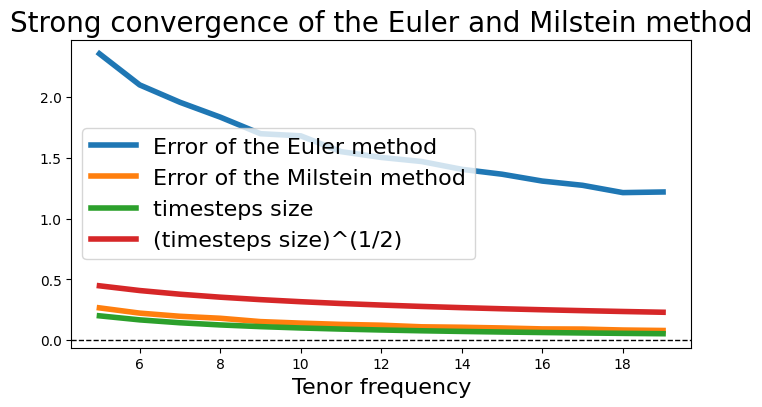

In [9]:
my_plotter(x=tenor_frequencies.tolist(), y=[errors_euler, errors_milstein, frequencies, square_root_frequencies],
           names=["Error of the Euler method", "Error of the Milstein method", "timesteps size", "(timesteps size)^(1/2)"],
           layout={"title": "Strong convergence of the Euler and Milstein method","x_label": "Tenor frequency"})

#the power on the "timesteps size" should be, when timesteps size tends to 0, proportionnal to the error of the Euler/Misltein method (depending on 
#whether the power is 1 or 1/2), this tends to be the case on the graph we obtain. Moreover, we also see how Milstein's method reduces the error (even
#for a timesteps size of 1/20. 

In [10]:
#SECOND PART OF THE HOMEWORK

und = Stock.TEST_COMPANY
ls = LongShort.LONG
strike = 1.2
expiry = 1
strike_level = strike * MarketData.get_spot()[und]
delta=0.01
Pricer.relative_bump_size=delta

model = FlatVolModel(und)
method = GreekMethod.BUMP

contract_fwd = ForwardContract(und, ls, strike_level, expiry)
contract_opt = EuropeanContract(und, PutCallFwd.PUT, ls, strike_level, expiry)

mc_params = MCParams(num_of_path=1000,
                     tenor_frequency=0,
                     antithetic=False,
                     standardize=False,
                     control_variate=False,
                     seed=1,
                     evolve_spot_method=MCNumMethod.EXACT)

pricer_fwd_mc = GenericMCPricer(contract_fwd, model, mc_params)
pricer_opt_mc = GenericMCPricer(contract_opt, model, mc_params)

#for the forward contract, calculation of the delta for the original and the new method.
fv_fwd_mc_delta_original = pricer_fwd_mc.calc_delta(method)
fv_fwd_mc_delta_modified = pricer_fwd_mc.calc_delta_scaling_initial(method,delta)

#for the option contract, calculation of the delta for the original and the new method. 
fv_opt_mc_delta_original = pricer_opt_mc.calc_delta(method)
fv_opt_mc_delta_modified = pricer_opt_mc.calc_delta_scaling_initial(method,delta)

print("ORIGINAL DELTA METHOD FWD: " + str(fv_fwd_mc_delta_original))
print("MODIFIED DELTA METHOD FWD: " + str(fv_fwd_mc_delta_modified))
print("ORIGINAL DELTA METHOD OPT: " + str(fv_opt_mc_delta_original))
print("MODIFIED DELTA METHOD OPT: " + str(fv_opt_mc_delta_modified))

ORIGINAL DELTA METHOD FWD: 1.0117703367162134
MODIFIED DELTA METHOD FWD: 1.0117703367162134
ORIGINAL DELTA METHOD OPT: -0.6154704997239158
MODIFIED DELTA METHOD OPT: -0.6154704997239158


In [11]:
#AI Usage to know the function "time"
import time 

Time_original = []
Time_modified = []
Delta_error = []

number_of_paths = np.arange(10, 10010, 1000)

for n in number_of_paths:
    mc_params = MCParams(num_of_path=n,
                     tenor_frequency=0,
                     antithetic=False,
                     standardize=False,
                     control_variate=False,
                     seed=1,
                     evolve_spot_method=MCNumMethod.EXACT)
    pricer_fwd_mc = GenericMCPricer(contract_fwd, model, mc_params)
    
    start = time.perf_counter()
    Delta_original = pricer_fwd_mc.calc_delta(method)
    time_original = time.perf_counter() - start
    Time_original.append(time_original)

    start = time.perf_counter()
    Delta_modified = pricer_fwd_mc.calc_delta_scaling_initial(method,delta)
    time_modified = time.perf_counter() - start
    Time_modified.append(time_modified)

    print("Difference between the two calculations of Delta for " + str(n) + " paths :" + str(Delta_original-Delta_modified))

#The difference is too small (what will differ is the time needed for calculation) so I didn't plot in two curves the deltas given by the two methods.
#So, I calculate the difference and I print its value for different numbers of paths. 

Difference between the two calculations of Delta for 10 paths :8.881784197001252e-16
Difference between the two calculations of Delta for 1010 paths :0.0
Difference between the two calculations of Delta for 2010 paths :-8.881784197001252e-16
Difference between the two calculations of Delta for 3010 paths :-8.881784197001252e-16
Difference between the two calculations of Delta for 4010 paths :0.0
Difference between the two calculations of Delta for 5010 paths :-1.7763568394002505e-15
Difference between the two calculations of Delta for 6010 paths :0.0
Difference between the two calculations of Delta for 7010 paths :-8.881784197001252e-16
Difference between the two calculations of Delta for 8010 paths :-1.7763568394002505e-15
Difference between the two calculations of Delta for 9010 paths :0.0


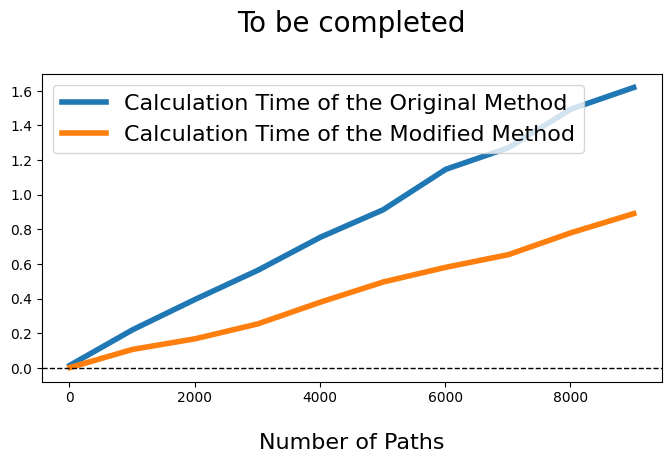

In [12]:
my_plotter(x=number_of_paths.tolist(), y=[Time_original,Time_modified],
           names=["Calculation Time of the Original Method", "Calculation Time of the Modified Method"],
           layout={"title": "To be completed","x_label": "Number of Paths"})

#The modified version is quicker than the previous one. This is due to the fact that we don't anymore simulate the spot path two times. 